# Step 01 - Data Preparation (Cleaning)
**UTS Deep Learning - Klasifikasi Citra Makanan Khas Yogyakarta (Bakpia, Gudeg, Sate Klathak)**

Notebooknya hanya boleh dijalankan **sekali** setiap kali dataset mentah berubah. Hasilnya adalah folder `data/processed/` berisi `train/`, `val/`, dan `test/` yang dipakai oleh notebook trainingnya. Maka kedua model akan memakai pembagian data yang **sama persis**.


**Alur:**
1. Seluruh file dataset gambar ada di `data/raw/(kelas_gambarnya)`
2. Validasi & standarisasi: file rusak, format tidak didukung, rotasi EXIF, konversi ke RGB, ukuran terlalu kecil, resize
3. Deteksi duplikat / hampir identik dengan perceptual hash
4. Cek visual per kelas + pengecualian manual
5. Split: **test dipisahkan lebih dulu** dari foto sendiri, sisanya train/val stratified
6. Cek kebocoran antar split
7. Simpan ke folder sudah benar
8. Ringkasan jumlah data + cek syarat minimal + contoh citra untuk BAB III

In [19]:
import os
import shutil
import random
import numpy as np

from pathlib import Path
import pandas as pd
from PIL import Image
from pillow_heif import register_heif_opener
register_heif_opener()                 # supaya Pillow bisa membuka file .heic

pd.set_option("display.width", 200)    # supaya tabel tidak terpotong "..."

ROOT = Path("..").resolve()        # = folder UTS (path lengkap, bukan relatif)
RAW  = ROOT / "data" / "raw"
CLASSES = ["bakpia", "gudeg", "sate_klathak"]   # = nama folder = label model
EXTS = {".jpg", ".jpeg", ".png", ".webp", ".heic", ".heif"}
SEED = 42                              # supaya hasil acak bisa diulang persis

for cls in CLASSES:
    print(cls, "->", (RAW / cls).exists())

bakpia -> True
gudeg -> True
sate_klathak -> True


In [ ]:
# ---------- Lokasi folder ----------
ROOT  = Path("..").resolve()               # = folder UTS (notebook ada di UTS/notebook/)
RAW   = ROOT / "data" / "raw"              # foto mentah, TIDAK pernah diubah
CLEAN = ROOT / "data" / "interim"            # hasil konversi + resize (sementara)
SPLIT = ROOT / "data" / "split"            # hasil akhir: train/val/test/<kelas>/
OUT   = ROOT / "outputs" / "cleaning"      # manifest, grid, tabel untuk laporan
OUT.mkdir(parents=True, exist_ok=True)

# ---------- Kelas & file ----------
CLASSES = ["bakpia", "gudeg", "sate_klathak"]      # = nama folder = label model
EXTS = {".jpg", ".jpeg", ".png", ".webp", ".heic", ".heif"}
MANUAL_EXCLUDE = {"sate_066.jpg", "sate_072.jpg"}  # hasil cek visual: tusuk bambu, bukan klathak

# ---------- Langkah 2–3: konversi & ukuran ----------
MAX_SIDE = 800          
MIN_SIDE = 128          

# ---------- Langkah 4–5: duplikat & grup anti-leakage ----------
PHASH_DUP = 8           # jarak pHash <= 8  -> duplikat, dibuang salah satu
PHASH_GROUP = 14        # jarak pHash <= 14 -> mirip, wajib di split yang sama
BURST_GAP_SEC = 10      # jepretan beruntun (perangkat sama, selisih <= 10 dtk) -> satu grup

# ---------- Langkah 6–7: split ----------
TEST_DEVICE = {         # foto dari perangkat ini ditahan untuk test (tidak pernah dilihat saat training)
    "bakpia": "FUJIFILM X-T30 III",
    "gudeg": "samsung Galaxy A35 5G",
    "sate_klathak": "samsung Galaxy A35 5G",
}
TEST_PER_CLASS = 20     # kalau foto perangkat itu kurang dari 20, ditambah foto internet
VAL_FRAC = 0.20
SEED = 42

# ---------- Syarat soal ----------
MIN_DEV, MIN_TEST, MIN_TOTAL = 100, 20, 360

for cls in CLASSES:
    print(f"{cls:13s} ada? {(RAW / cls).exists()}")
print("Output ke:", SPLIT)

bakpia        ada? True
gudeg         ada? True
sate_klathak  ada? True
Output ke: D:\Kuliah\Semester 5\Deep Learning\UTS\data\split


## Pengecekan Metadata terlebih dahulu dan ringkasan dataset, dan pengumpulan data

In [10]:
def read_meta(path):
    """Baca perangkat dan waktu pengambilan dari EXIF. Foto internet biasanya tidak punya."""
    try:
        with Image.open(path) as im:
            exif = im.getexif()
            device = f"{exif.get(271, '')} {exif.get(272, '')}".strip()   # 271 = merek, 272 = model
            t = exif.get_ifd(0x8769).get(36867) or exif.get(306)          # 36867 = waktu jepret, 306 = cadangan
        t = str(t).strip("\x00 ") if t else None
        taken = pd.to_datetime(t, format="%Y:%m:%d %H:%M:%S", errors="coerce") if t else pd.NaT
        return device, taken, "ok"
    except Exception as e:
        return "", pd.NaT, f"rusak:{type(e).__name__}"

rows = []
for cls in CLASSES:
    folder = RAW / cls
    for i, p in enumerate(sorted(folder.rglob("*")), 1):
        rel = p.relative_to(folder)
        if not p.is_file() or any(part.startswith((".", "_")) for part in rel.parts):
            continue                                   # lewati folder, _dibuang, file tersembunyi
        source = "internet" if len(rel.parts) == 1 else "sendiri"
        device, taken, status = read_meta(p)
        rows.append(dict(uid=f"{cls}_{i:04d}", cls=cls, source=source, path=str(p),
                         ext=p.suffix.lower(), device=device, taken_at=taken, status=status))

df = pd.DataFrame(rows)
df.loc[~df.ext.isin(EXTS), "status"] = "format_tidak_didukung"

print(pd.crosstab(df.cls, df.source, margins=True, margins_name="total"), "\n")
print(df.status.value_counts(), "\n")
own = df[df.source == "sendiri"]
print(own.groupby(["cls", "device"]).agg(jumlah=("uid", "size"),
                                         mulai=("taken_at", "min"),
                                         selesai=("taken_at", "max")))

source        internet  sendiri  total
cls                                   
bakpia              55       71    126
gudeg               64       63    127
sate_klathak        80       70    150
total              199      204    403 

status
ok    403
Name: count, dtype: int64 

                                          jumlah               mulai             selesai
cls          device                                                                     
bakpia       FUJIFILM X-T30 III               21 2026-10-21 10:42:35 2026-10-21 10:55:30
             Xiaomi Redmi Note 13 Pro 5G      42 2026-10-20 19:54:19 2026-10-20 19:57:43
             samsung Galaxy A35 5G             8 2026-10-20 19:53:46 2026-10-20 19:55:47
gudeg        Xiaomi Redmi Note 13 Pro 5G      51 2026-10-20 19:59:16 2026-10-20 20:02:34
             samsung Galaxy A35 5G            12 2026-10-20 19:56:32 2026-10-20 20:08:38
sate_klathak FUJIFILM X-T30 III               26 2026-10-22 15:29:32 2026-10-22 15:37:08
       

## 2. Validasi & standarisasi

Setiap foto dibuka dan diproses dengan langkah yang sama:
- **Format tidak didukung** (bukan gambar) -> dibuang
- **File rusak** (tidak bisa dibuka) -> dibuang
- **Rotasi EXIF diperbaiki**: foto HP sering tersimpan miring dan hanya tampil benar di galeri karena tag EXIF. Tanpa perbaikan ini, model melihat foto dalam posisi miring/terbalik.
- **Konversi ke RGB**: PNG transparan ditempel di latar putih (bukan hitam), grayscale/CMYK diubah ke RGB
- **Terlalu kecil** (sisi terpendek < `MIN_SIDE`) -> dibuang
- **Terlalu besar** -> diperkecil sampai sisi terpanjang = `MAX_SIDE` (rasio dipertahankan). Resize ke 224x224 dilakukan nanti di notebook training.
- **Pengecekan Frame terbesar dan terkecil**
- **Ringkasan Hasil**

Hasil disimpan sementara di `data/interim/`.

status        dibuang   ok  total
cls                              
bakpia              0  126    126
gudeg               0  127    127
sate_klathak        2  148    150
total               2  401    403 

              uid   source                                                                      path         reason
sate_klathak_0137 internet D:\Kuliah\Semester 5\Deep Learning\UTS\data\raw\sate_klathak\sate_066.jpg manual_exclude
sate_klathak_0143 internet D:\Kuliah\Semester 5\Deep Learning\UTS\data\raw\sate_klathak\sate_072.jpg manual_exclude 

Sisi terpendek foto (px):
 count     401.0
mean     1943.0
std      1470.0
min       183.0
25%       527.0
50%      2296.0
75%      3060.0
max      6144.0 

              uid   source  width  height
sate_klathak_0109 internet    275     183
sate_klathak_0140 internet    259     194
      bakpia_0005 internet    263     222
       gudeg_0056 internet    304     226
      bakpia_0019 internet    439     239
      bakpia_0053 internet    330  

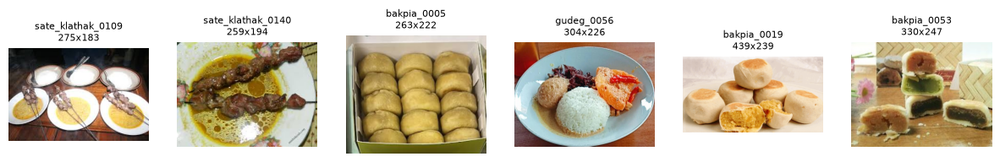

In [11]:
import shutil
from PIL import ImageOps
import matplotlib.pyplot as plt

def to_rgb(img):
    """PNG transparan -> ditempel di latar putih; grayscale/CMYK/palette -> RGB."""
    if img.mode in ("RGBA", "LA") or (img.mode == "P" and "transparency" in img.info):
        img = img.convert("RGBA")
        bg = Image.new("RGB", img.size, (255, 255, 255))
        bg.paste(img, mask=img.getchannel("A"))
        return bg
    return img.convert("RGB")

if CLEAN.exists():
    shutil.rmtree(CLEAN)                 # folder turunan
for cls in CLASSES:
    (CLEAN / cls).mkdir(parents=True)

# tandai yang sudah pasti dibuang sebelum diproses
df["reason"] = ""
bad = df.status != "ok"                  # rusak / format tidak didukung dari langkah 1
df.loc[bad, "reason"] = df.loc[bad, "status"]
df.loc[bad, "status"] = "dibuang"
manual = df.path.map(lambda p: Path(p).name).isin(MANUAL_EXCLUDE)
df.loc[manual, ["status", "reason"]] = ["dibuang", "manual_exclude"]

df["width"], df["height"], df["clean_path"] = 0, 0, ""
for i, r in df[df.status == "ok"].iterrows():
    try:
        with Image.open(r.path) as im:
            im.verify()                                   # 1) cek file rusak/terpotong
        with Image.open(r.path) as im:
            im = to_rgb(ImageOps.exif_transpose(im))      # 2) putar sesuai EXIF, 3) jadikan RGB
        w, h = im.size
        df.loc[i, ["width", "height"]] = [w, h]           # ukuran asli (setelah diputar)
        if min(w, h) < MIN_SIDE:                          # 4) terlalu kecil -> buang
            df.loc[i, ["status", "reason"]] = ["dibuang", "terlalu_kecil"]
            continue
        if max(w, h) > MAX_SIDE:                          # 5) terlalu besar -> perkecil, rasio tetap
            im.thumbnail((MAX_SIDE, MAX_SIDE), Image.LANCZOS)
        out = CLEAN / r.cls / f"{r.uid}.png"
        im.save(out)
        df.loc[i, "clean_path"] = str(out)
    except Exception as e:
        df.loc[i, ["status", "reason"]] = ["dibuang", f"rusak:{type(e).__name__}"]

# ---------- ringkasan ----------
print(pd.crosstab(df.cls, df.status, margins=True, margins_name="total"), "\n")
print(df.loc[df.status == "dibuang", ["uid", "source", "path", "reason"]].to_string(index=False), "\n")

ok = df[df.status == "ok"].copy()
ok["min_side"] = ok[["width", "height"]].min(axis=1)
print("Sisi terpendek foto (px):\n", ok.min_side.describe().round(0).to_string(), "\n")
smallest = ok.nsmallest(6, "min_side")
print(smallest[["uid", "source", "width", "height"]].to_string(index=False))

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, r in zip(axes, smallest.itertuples()):
    ax.imshow(Image.open(r.clean_path))
    ax.set_title(f"{r.uid}\n{r.width}x{r.height}", fontsize=8); ax.axis("off")
plt.show()

## 3. Deteksi duplikat dengan perceptual hash (pHash)
Setiap foto diringkas menjadi "sidik jari" 64 bit berdasarkan pola terang-gelapnya (pHash).
Dua foto yang tampak sama (walau beda ukuran, format, atau kompresi) punya sidik jari yang hampir sama.
Jarak Hamming = jumlah bit yang berbeda (0 = identik, 64 = sangat berbeda).
- Jarak <= `PHASH_DUP` (8) -> dianggap duplikat, disimpan satu saja
  (prioritas: foto sendiri, lalu resolusi terbesar)
- Duplikat yang berada di **kelas berbeda** -> label ambigu, semua dibuang

Pasangan duplikat: 13 | foto lintas kelas: 0

reason        duplikat  manual_exclude   ok  total
cls                                               
bakpia               1               0  125    126
gudeg                3               0  124    127
sate_klathak         9               2  139    150
total               13               2  388    403


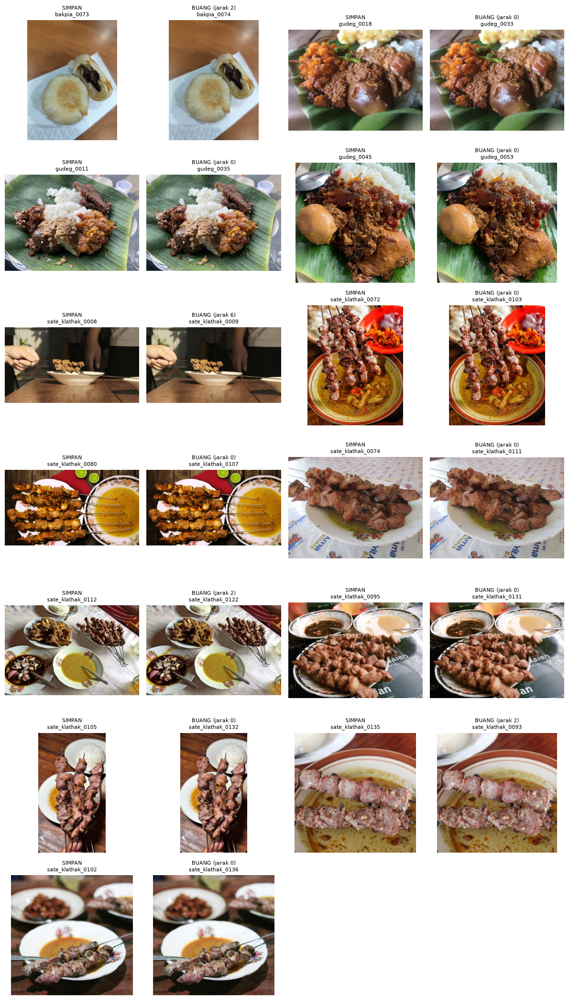

In [12]:
import numpy as np
import imagehash

alive = df[df.status == "ok"].copy()
hashes = [imagehash.phash(Image.open(p)) for p in alive.clean_path]       # sidik jari 64 bit per foto
bits = np.array([h.hash.flatten() for h in hashes], dtype=np.uint8)
D = (bits[:, None, :] != bits[None, :, :]).sum(-1)                         # jarak Hamming semua pasangan (N x N)
pos = {u: k for k, u in enumerate(alive.uid)}                               # uid -> nomor baris/kolom di D

def clusters(M):
    """Gabungkan semua pasangan yang M[i, j] = True menjadi satu klaster (union-find)."""
    parent = list(range(len(M)))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    for i, j in np.argwhere(np.triu(M, 1)):
        parent[find(i)] = find(j)
    return np.array([find(i) for i in range(len(M))])

alive["dup"] = clusters(D <= PHASH_DUP)
alive["pix"] = alive.width * alive.height

pairs, cross = [], []
for _, g in alive.groupby("dup"):
    if len(g) == 1:
        continue                                      # tidak punya kembaran
    if g.cls.nunique() > 1:
        cross += list(g.uid); continue                # foto sama di kelas berbeda -> label ambigu
    g = g.assign(prio=g.source == "internet").sort_values(["prio", "pix"], ascending=[True, False])
    keep = g.uid.iloc[0]                              # simpan: foto sendiri dulu, lalu resolusi terbesar
    for u in g.uid.iloc[1:]:
        pairs.append((keep, u, int(D[pos[keep], pos[u]])))

df.loc[df.uid.isin([u for _, u, _ in pairs]), ["status", "reason"]] = ["dibuang", "duplikat"]
df.loc[df.uid.isin(cross), ["status", "reason"]] = ["dibuang", "duplikat_lintas_kelas"]

print(f"Pasangan duplikat: {len(pairs)} | foto lintas kelas: {len(cross)}\n")
print(pd.crosstab(df.cls, df.reason.replace("", "ok"), margins=True, margins_name="total"))

# ---------- cek visual: kiri disimpan, kanan dibuang ----------
paths = df.set_index("uid").clean_path
ncols = 4
nrows = max(1, (2 * len(pairs) + ncols - 1) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3 * nrows), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for k, (keep, drop, d) in enumerate(pairs):
    for j, (u, label) in enumerate([(keep, "SIMPAN"), (drop, f"BUANG (jarak {d})")]):
        ax = axes.ravel()[2 * k + j]
        ax.imshow(Image.open(paths[u])); ax.set_title(f"{label}\n{u}", fontsize=8)
plt.tight_layout(); plt.show()

## 4. Grup anti-leakage
Foto yang "mirip-mirip" harus selalu masuk split yang sama (train/val/test),
supaya model tidak diuji dengan foto yang praktis sudah pernah dilihat.
Dua foto dimasukkan ke grup yang sama jika:
1. **Mirip secara visual**: jarak pHash <= `PHASH_GROUP` (14), atau
2. **Jepretan beruntun**: foto sendiri dari **perangkat yang sama** dengan selisih waktu <= `BURST_GAP_SEC` (10 detik).

Aturan 2 dihitung per perangkat karena foto sate diambil serentak oleh 4 HP/kamera;
jika digabung per folder, foto dari HP berbeda ikut tersambung hanya karena waktunya berdekatan.
Grup tidak boleh lintas kelas. Split dilakukan per grup, bukan per foto.

Pasangan jepretan beruntun yang digabung: 113 

              foto  jumlah_grup  grup_tunggal  grup_terbesar
cls                                                         
bakpia         125           82            76             35
gudeg          124           69            65             48
sate_klathak   139          109            96             14 

8 grup terbesar:
                cls   n  internet  sendiri                                        perangkat
group                                                                                      
238           gudeg  48         1       47                      Xiaomi Redmi Note 13 Pro 5G
95           bakpia  35         0       35                      Xiaomi Redmi Note 13 Pro 5G
315    sate_klathak  14         0       14  Xiaomi POCO X7 Pro, Xiaomi Redmi Note 13 Pro 5G
60           bakpia   6         0        6                      Xiaomi Redmi Note 13 Pro 5G
248           gudeg   5         0        5                            samsun

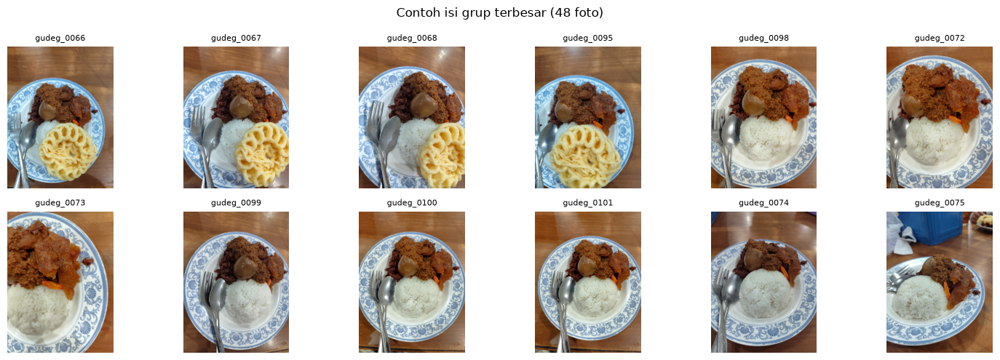

In [13]:
final = df[df.status == "ok"].copy()
ii = [pos[u] for u in final.uid]
link = D[np.ix_(ii, ii)] <= PHASH_GROUP                   # (1) mirip secara visual
c = final.cls.to_numpy(dtype=str)
link &= c[:, None] == c[None, :]                          # grup tidak boleh lintas kelas
k = {u: n for n, u in enumerate(final.uid)}               # uid -> nomor baris/kolom di link

n_burst = 0
own = final[(final.source == "sendiri") & final.taken_at.notna()]
for _, g in own.groupby(["cls", "device"]):                # (2) jepretan beruntun, per perangkat
    g = g.sort_values("taken_at")
    for a, b, ta, tb in zip(g.uid, g.uid.iloc[1:], g.taken_at, g.taken_at.iloc[1:]):
        if (tb - ta).total_seconds() <= BURST_GAP_SEC:
            link[k[a], k[b]] = link[k[b], k[a]] = True
            n_burst += 1

final["group"] = clusters(link)

# ---------- ringkasan ----------
gs = final.groupby("group").agg(cls=("cls", "first"), n=("uid", "size"),
                                internet=("source", lambda s: (s == "internet").sum()),
                                sendiri=("source", lambda s: (s == "sendiri").sum()),
                                perangkat=("device", lambda s: ", ".join(sorted(set(s) - {""}))))
print("Pasangan jepretan beruntun yang digabung:", n_burst, "\n")
print(gs.groupby("cls").agg(foto=("n", "sum"), jumlah_grup=("n", "size"),
                            grup_tunggal=("n", lambda s: (s == 1).sum()),
                            grup_terbesar=("n", "max")), "\n")
print("8 grup terbesar:")
print(gs.sort_values("n", ascending=False).head(8).to_string())

# ---------- cek visual: isi grup terbesar ----------
big = gs.n.idxmax()
members = final[final.group == big].sort_values("taken_at").uid.tolist()[:12]
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for ax in axes.ravel():
    ax.axis("off")
for ax, u in zip(axes.ravel(), members):
    ax.imshow(Image.open(paths[u])); ax.set_title(u, fontsize=8)
fig.suptitle(f"Contoh isi grup terbesar ({gs.n.max()} foto)")
plt.tight_layout(); plt.show()

## 5. Split train / val / test (per grup)
- **Test**: semua grup yang berisi foto dari perangkat yang ditahan (`TEST_DEVICE`).
  Perangkat ini tidak pernah dilihat model saat training. Jika jumlahnya < 20,
  ditambah grup foto internet sampai 20.
- **Train / val**: sisa grup dibagi 80:20, terpisah untuk foto internet dan foto sendiri,
  supaya val berisi campuran yang sama dengan train.
- Pembagian selalu **per grup utuh** (hasil langkah 4), tidak pernah per foto.

In [14]:
rng = np.random.RandomState(SEED)
final["split"] = ""

def take_groups(part, n_target):
    """Ambil grup utuh secara acak sampai jumlah fotonya mencapai n_target (tidak melebihi)."""
    sizes = part.groupby("group").size()
    gids = sizes.index.to_numpy().copy()
    rng.shuffle(gids)
    chosen, n = [], 0
    for g in gids:
        if n + sizes[g] <= n_target:
            chosen.append(g); n += sizes[g]
    return chosen

for cls in CLASSES:
    sub = final[final.cls == cls]
    gsrc = sub.groupby("group").source.agg(lambda s: s.mode()[0])      # sumber mayoritas tiap grup

    # (a) test inti: semua grup yang berisi foto dari perangkat yang ditahan
    test_groups = set(sub.loc[sub.device == TEST_DEVICE[cls], "group"])
    n_test = int(sub.group.isin(test_groups).sum())

    # (b) kalau kurang dari TEST_PER_CLASS, tambah grup foto internet
    if n_test < TEST_PER_CLASS:
        pool = sub[(sub.group.map(gsrc) == "internet") & ~sub.group.isin(test_groups)]
        test_groups |= set(take_groups(pool, TEST_PER_CLASS - n_test))
    final.loc[sub.index[sub.group.isin(test_groups)], "split"] = "test"

    # (c) sisanya (dev) dibagi train/val per grup, proporsional per sumber
    dev = sub[~sub.group.isin(test_groups)]
    for src in ["internet", "sendiri"]:
        part = dev[dev.group.map(gsrc) == src]
        val_groups = take_groups(part, round(VAL_FRAC * len(part)))
        final.loc[part.index, "split"] = np.where(part.group.isin(val_groups), "val", "train")

print(pd.crosstab(final.cls, final.split, margins=True, margins_name="total")[["train", "val", "test", "total"]], "\n")
print(pd.crosstab([final.cls, final.source], final.split)[["train", "val", "test"]])

split         train  val  test  total
cls                                  
bakpia           83   21    21    125
gudeg            90   14    20    124
sate_klathak     95   24    20    139
total           268   59    61    388 

split                  train  val  test
cls          source                    
bakpia       internet     44   11     0
             sendiri      39   10    21
gudeg        internet     43   10     8
             sendiri      47    4    12
sate_klathak internet     56   14     0
             sendiri      39   10    20


In [15]:
# 1) setiap grup hanya ada di satu split
assert final.groupby("group").split.nunique().max() == 1, "Ada grup yang terpecah antar split!"

# 2) tidak ada foto mirip (pHash <= PHASH_GROUP) antar split dalam kelas yang sama
for cls in CLASSES:
    sub = final[final.cls == cls]
    for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
        ia = [pos[u] for u in sub.uid[sub.split == a]]
        ib = [pos[u] for u in sub.uid[sub.split == b]]
        m = D[np.ix_(ia, ib)].min()
        print(f"{cls:13s} jarak pHash terkecil {a:5s}<->{b:4s}: {m}")
        assert m > PHASH_GROUP, f"{cls}: ada foto mirip antara {a} dan {b}!"

# 3) foto dari perangkat test tidak pernah masuk train/val
for cls in CLASSES:
    bocor = final[(final.cls == cls) & (final.device == TEST_DEVICE[cls]) & (final.split != "test")]
    assert bocor.empty, f"{cls}: {len(bocor)} foto perangkat test masuk train/val!"

# 4) syarat jumlah soal
counts = pd.crosstab(final.cls, final.split)
for cls in CLASSES:
    dev_n, test_n = counts.loc[cls, ["train", "val"]].sum(), counts.loc[cls, "test"]
    status = "OK" if dev_n >= MIN_DEV and test_n >= MIN_TEST else "BELUM MEMENUHI"
    print(f"{cls:13s} dev={dev_n:3d} (min {MIN_DEV}) | test={test_n:2d} (min {MIN_TEST}) -> {status}")
print(f"total={len(final)} (min {MIN_TOTAL}) ->", "OK" if len(final) >= MIN_TOTAL else "BELUM MEMENUHI")
print("\nSemua pengecekan anti-leakage lolos.")

bakpia        jarak pHash terkecil train<->val : 16
bakpia        jarak pHash terkecil train<->test: 18
bakpia        jarak pHash terkecil val  <->test: 20
gudeg         jarak pHash terkecil train<->val : 16
gudeg         jarak pHash terkecil train<->test: 18
gudeg         jarak pHash terkecil val  <->test: 20
sate_klathak  jarak pHash terkecil train<->val : 16
sate_klathak  jarak pHash terkecil train<->test: 18
sate_klathak  jarak pHash terkecil val  <->test: 20
bakpia        dev=104 (min 100) | test=21 (min 20) -> OK
gudeg         dev=104 (min 100) | test=20 (min 20) -> OK
sate_klathak  dev=119 (min 100) | test=20 (min 20) -> OK
total=388 (min 360) -> OK

Semua pengecekan anti-leakage lolos.


## SIMPAN HASIL CLEANING KE PROCESSED

Menyimpan hasil cleaning ke folder **data/processed/**, serta membuat file **manifest.csv** yang berfungsi sebagai tracking data apa saja yang berubah setelah di cleaning.

In [16]:
if SPLIT.exists():
    shutil.rmtree(SPLIT)                       # folder turunan, dibuat ulang dari awal
final = final.sort_values(["cls", "split", "uid"])
final["final_name"] = ""
for cls, g in final.groupby("cls"):
    for n, (i, r) in enumerate(g.iterrows(), 1):
        name = f"{cls}_{n:03d}.png"            # nomor unik per kelas, lintas split
        dst = SPLIT / r.split / cls / name
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(r.clean_path, dst)
        final.loc[i, "final_name"] = name

manifest = df.merge(final[["uid", "group", "split", "final_name"]], on="uid", how="left")
manifest.to_csv(OUT / "manifest.csv", index=False)

print("Manifest:", OUT / "manifest.csv")
for sp in ["train", "val", "test"]:
    print(f"{sp:5s}", {cls: len(list((SPLIT / sp / cls).glob("*.png"))) for cls in CLASSES})

Manifest: D:\Kuliah\Semester 5\Deep Learning\UTS\outputs\cleaning\manifest.csv
train {'bakpia': 83, 'gudeg': 90, 'sate_klathak': 95}
val   {'bakpia': 21, 'gudeg': 14, 'sate_klathak': 24}
test  {'bakpia': 21, 'gudeg': 20, 'sate_klathak': 20}


## RINGKASAN UNTUK BAB III

## 8. Cek visual akhir
Semua citra hasil akhir ditampilkan per kelas dan per split untuk memastikan
tidak ada salah label, kolase, watermark besar, atau foto yang bukan makanannya.

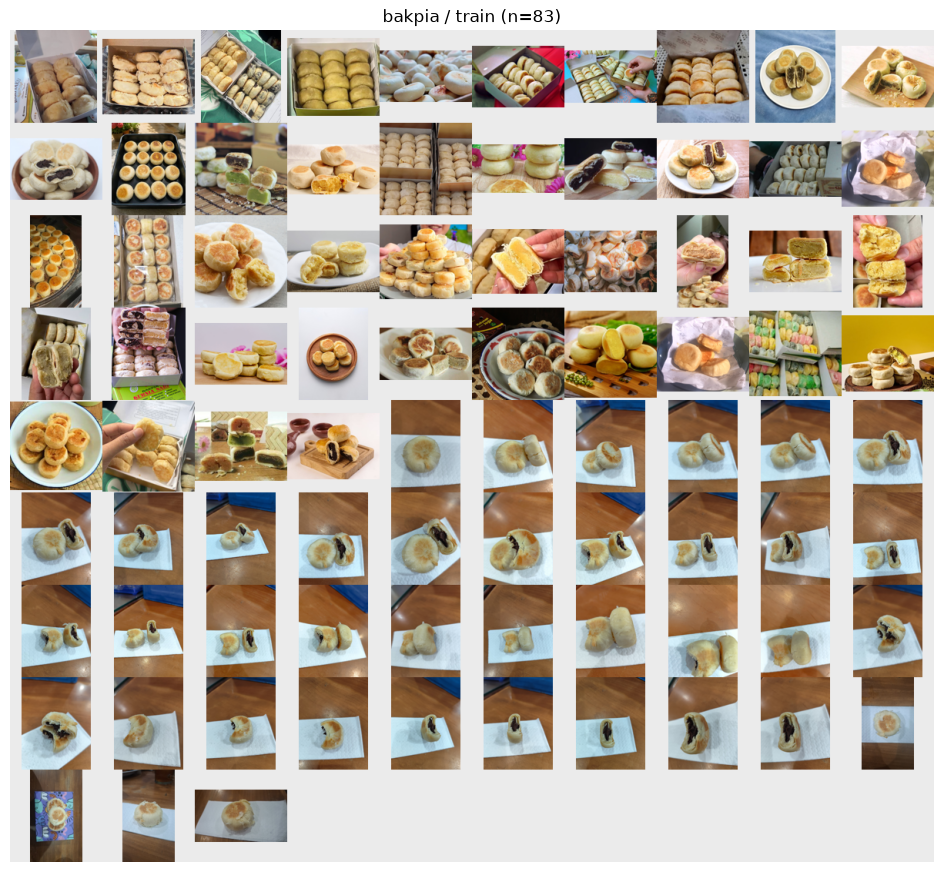

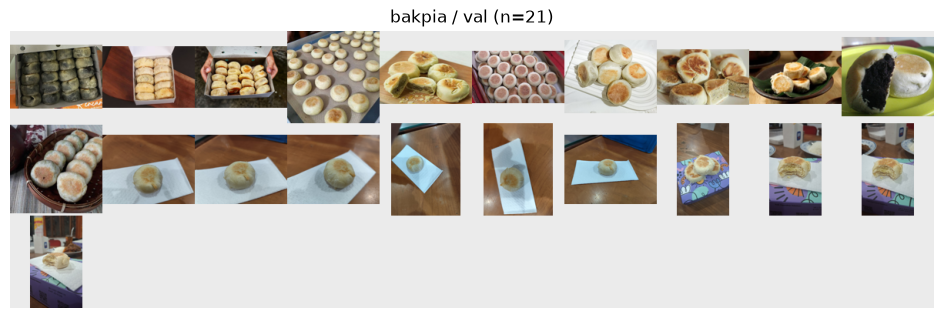

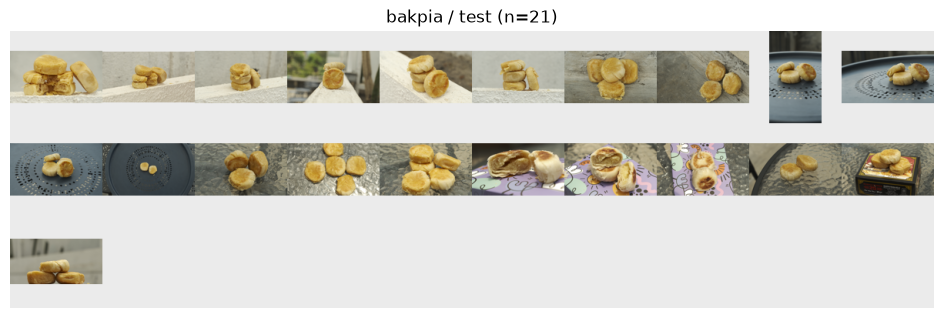

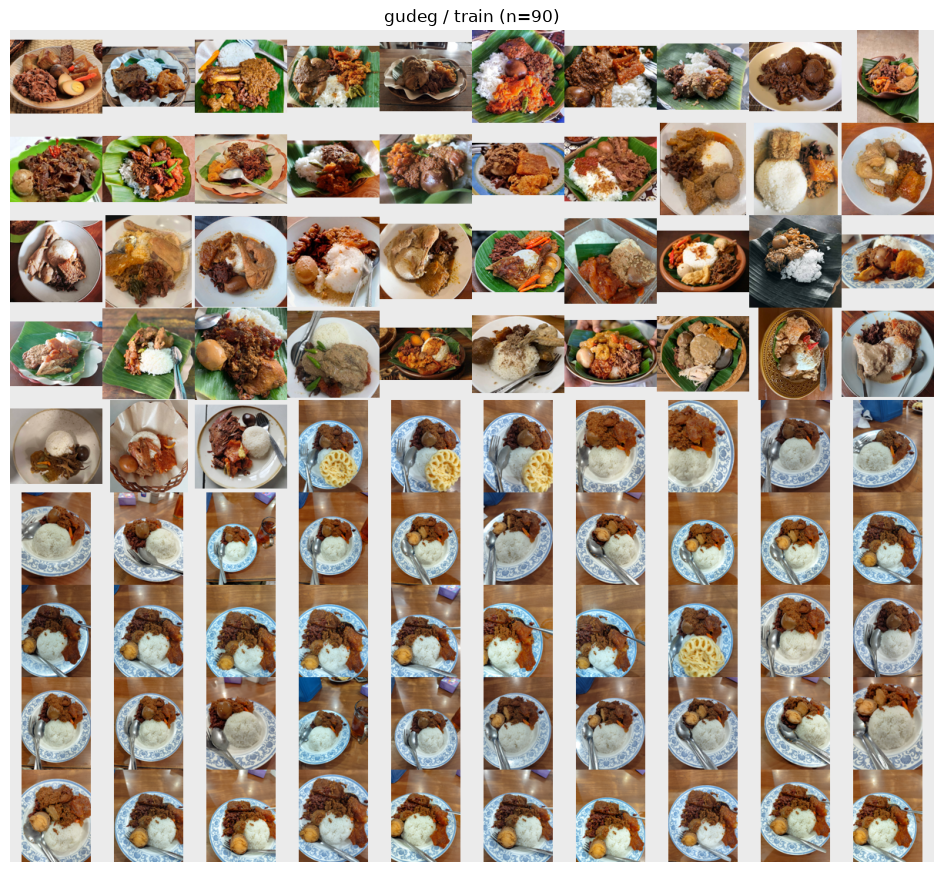

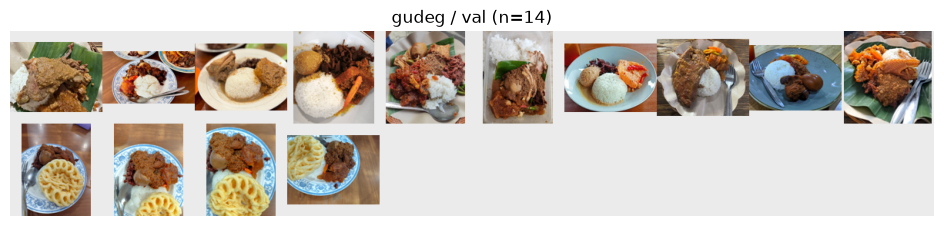

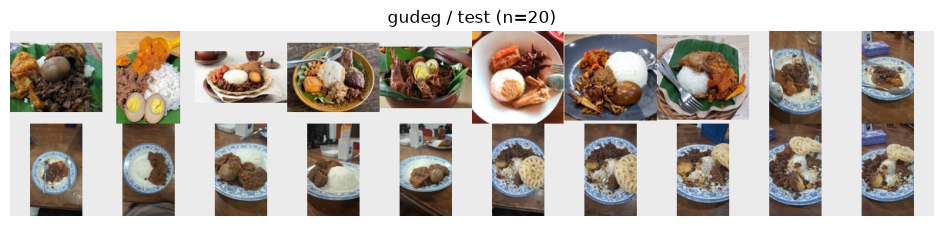

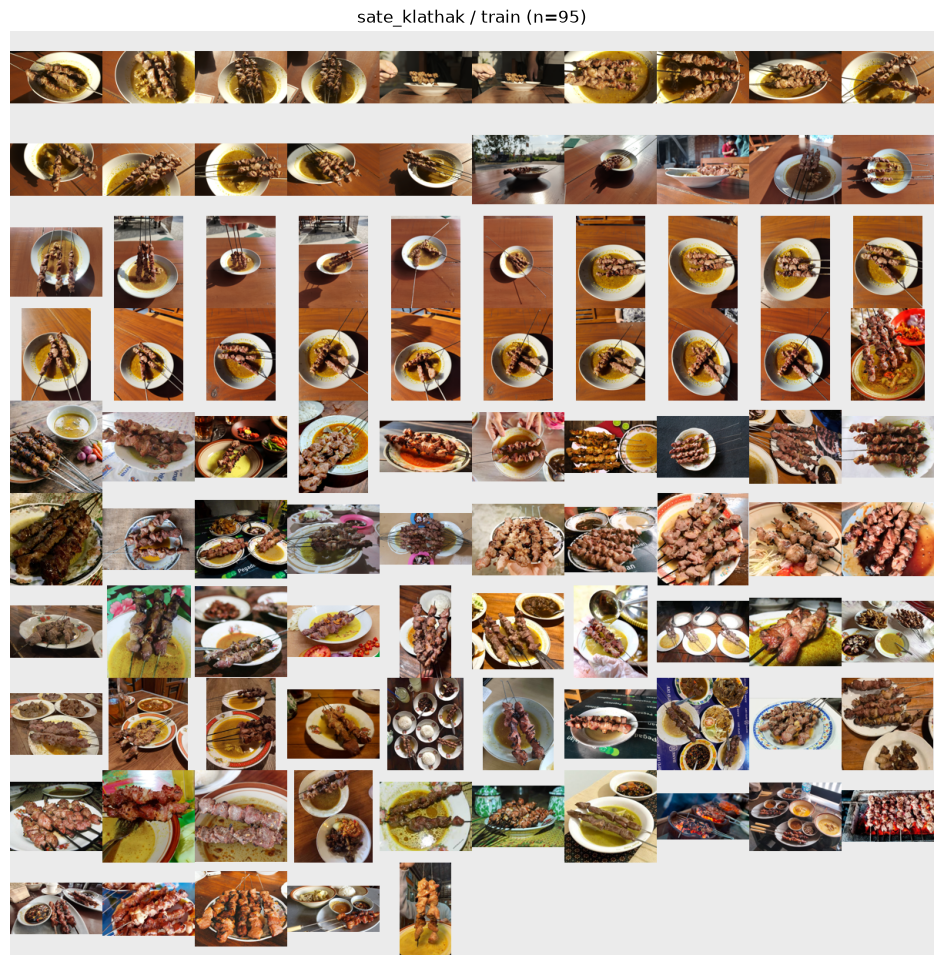

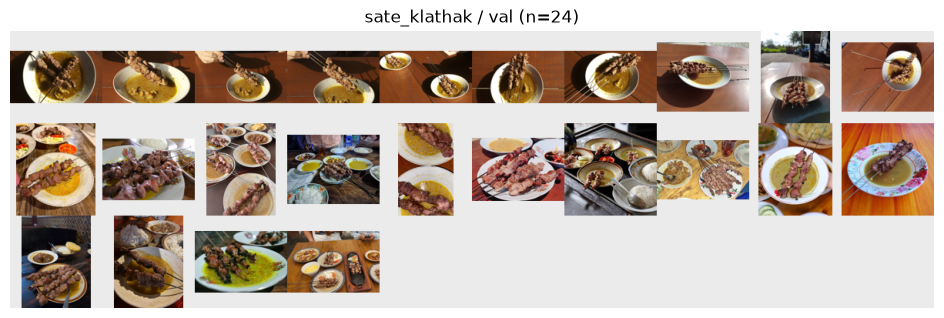

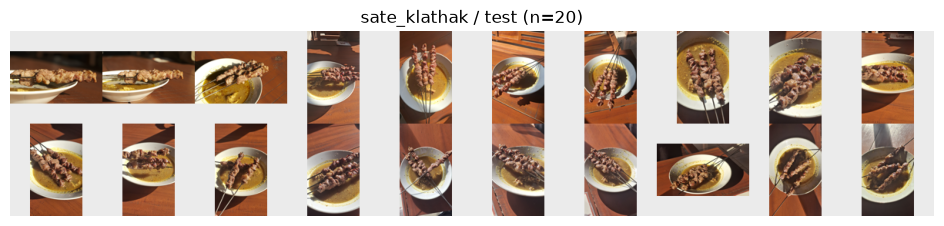

In [17]:
from PIL import ImageOps

def contact_sheet(paths, ncols=10, thumb=120):
    """Gabungkan banyak foto menjadi satu gambar kotak-kotak (thumbnail)."""
    rows = (len(paths) + ncols - 1) // ncols
    sheet = Image.new("RGB", (ncols * thumb, rows * thumb), (235, 235, 235))
    for k, p in enumerate(paths):
        with Image.open(p) as im:
            im = ImageOps.pad(im.convert("RGB"), (thumb, thumb), color=(235, 235, 235))
        sheet.paste(im, ((k % ncols) * thumb, (k // ncols) * thumb))
    return sheet

(OUT / "grids").mkdir(exist_ok=True)
for cls in CLASSES:
    for sp in ["train", "val", "test"]:
        paths = sorted((SPLIT / sp / cls).glob("*.png"))
        sheet = contact_sheet(paths)
        sheet.save(OUT / "grids" / f"{cls}_{sp}.jpg", quality=85)
        plt.figure(figsize=(12, 12 * sheet.height / sheet.width))
        plt.imshow(sheet); plt.axis("off"); plt.title(f"{cls} / {sp} (n={len(paths)})")
        plt.show()

## 9. Ringkasan dataset (bahan BAB III)
Semua tabel di bawah disimpan ke `outputs/cleaning/` dan dapat langsung dipakai di laporan.

Tabel 3.x  Alur pembersihan data


reason,foto_mentah,duplikat,lolos,manual_exclude
cls,,,,
bakpia,126,1,125,0
gudeg,127,3,124,0
sate_klathak,150,9,139,2
total,403,13,388,2


Tabel 3.x  Jumlah citra per kelas dan split


split,train,val,test,total
cls,,,,
bakpia,83,21,21,125
gudeg,90,14,20,124
sate_klathak,95,24,20,139
total,268,59,61,388


Tabel 3.x  Komposisi sumber (internet / foto sendiri) per split


...

,jumlah_grup,grup_terbesar,grup_tunggal
cls,,,
bakpia,82,35,76
gudeg,69,48,65
sate_klathak,109,14,96


Tabel 3.x  Pemenuhan syarat dataset


,syarat,jumlah,lulus
0,bakpia: train+val >= 100,104,True
1,bakpia: test >= 20,21,True
2,gudeg: train+val >= 100,104,True
3,gudeg: test >= 20,20,True
4,sate_klathak: train+val >= 100,119,True
5,sate_klathak: test >= 20,20,True
6,total >= 360,388,True


Tabel 3.x  Parameter cleaning


,parameter,nilai,keterangan
0,MAX_SIDE,800,sisi terpanjang setelah resize (px)
1,MIN_SIDE,128,sisi terpendek minimal (px)
2,PHASH_DUP,8,jarak pHash maksimal untuk duplikat
3,PHASH_GROUP,14,jarak pHash maksimal untuk satu grup
4,BURST_GAP_SEC,10,jeda jepretan beruntun per perangkat (detik)
5,VAL_FRAC,0.2,proporsi validation dari dev
6,TEST_PER_CLASS,20,jumlah minimal test per kelas
7,SEED,42,seed pengacakan


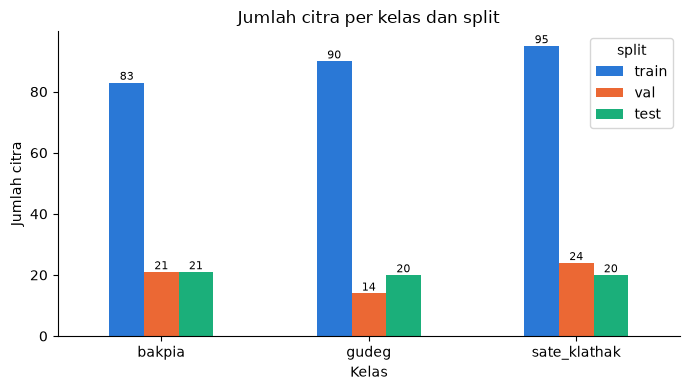

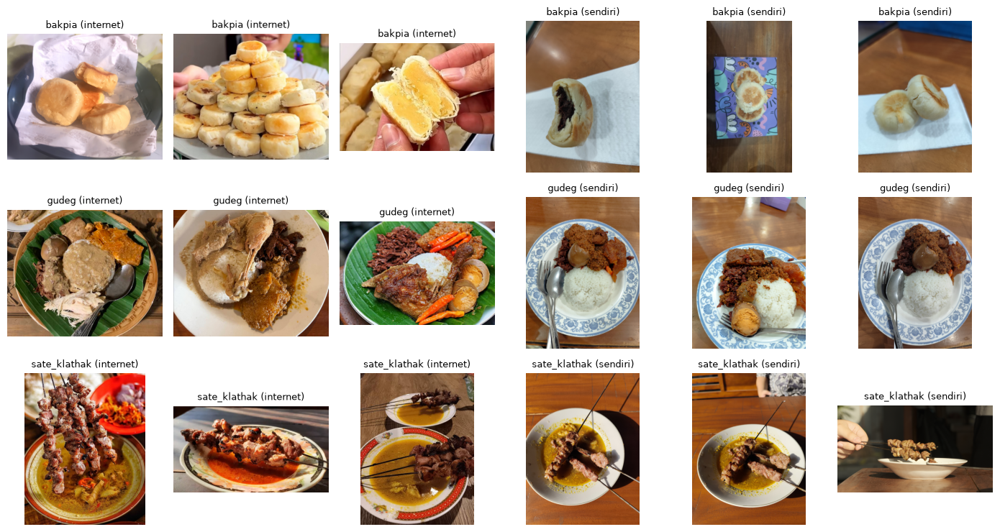

In [18]:
# 9a. Alur pembersihan: dari foto mentah sampai foto akhir
alasan = manifest.reason.replace("", "lolos")
alur = pd.crosstab(manifest.cls, alasan)
alur.insert(0, "foto_mentah", alur.sum(axis=1))
alur.loc["total"] = alur.sum()
print("Tabel 3.x  Alur pembersihan data"); display(alur)

# 9b. Jumlah akhir per kelas dan split
tabel_split = pd.crosstab(final.cls, final.split, margins=True, margins_name="total")[["train", "val", "test", "total"]]
print("Tabel 3.x  Jumlah citra per kelas dan split"); display(tabel_split)

# 9c. Komposisi sumber per split
print("Tabel 3.x  Komposisi sumber (internet / foto sendiri) per split")
display(pd.crosstab([final.cls, final.source], final.split)[["train", "val", "test"]])

# 9d. Asal citra test: perangkat yang ditahan + tambahan internet
t = final[final.split == "test"]
asal = pd.Series(np.where(t.source == "internet", "internet", t.device), index=t.index, name="asal")
print("Tabel 3.x  Asal citra test set"); display(pd.crosstab(t.cls, asal, margins=True, margins_name="total"))

# 9e. Statistik grup anti-leakage
gstat = (final.groupby(["cls", "group"]).size().groupby("cls")
         .agg(jumlah_grup="size", grup_terbesar="max", grup_tunggal=lambda s: (s == 1).sum()))
print("Tabel 3.x  Statistik grup anti-leakage"); display(gstat)

# 9f. Cek syarat minimal soal
rows = []
for cls in CLASSES:
    n_dev = int(((final.cls == cls) & final.split.isin(["train", "val"])).sum())
    n_test = int(((final.cls == cls) & (final.split == "test")).sum())
    rows += [(f"{cls}: train+val >= {MIN_DEV}", n_dev, n_dev >= MIN_DEV),
             (f"{cls}: test >= {MIN_TEST}", n_test, n_test >= MIN_TEST)]
rows.append((f"total >= {MIN_TOTAL}", len(final), len(final) >= MIN_TOTAL))
syarat = pd.DataFrame(rows, columns=["syarat", "jumlah", "lulus"])
print("Tabel 3.x  Pemenuhan syarat dataset"); display(syarat)

# 9g. Parameter cleaning
param = pd.DataFrame({
    "parameter": ["MAX_SIDE", "MIN_SIDE", "PHASH_DUP", "PHASH_GROUP", "BURST_GAP_SEC", "VAL_FRAC", "TEST_PER_CLASS", "SEED"],
    "nilai": [str(v) for v in [MAX_SIDE, MIN_SIDE, PHASH_DUP, PHASH_GROUP, BURST_GAP_SEC, VAL_FRAC, TEST_PER_CLASS, SEED]],
    "keterangan": ["sisi terpanjang setelah resize (px)", "sisi terpendek minimal (px)",
                   "jarak pHash maksimal untuk duplikat", "jarak pHash maksimal untuk satu grup",
                   "jeda jepretan beruntun per perangkat (detik)", "proporsi validation dari dev",
                   "jumlah minimal test per kelas", "seed pengacakan"]})
print("Tabel 3.x  Parameter cleaning"); display(param)

# simpan tabel untuk laporan
alur.to_csv(OUT / "tabel_alur_pembersihan.csv")
tabel_split.to_csv(OUT / "tabel_split.csv")
syarat.to_csv(OUT / "tabel_syarat.csv", index=False)
param.to_csv(OUT / "tabel_parameter.csv", index=False)

# 9h. Grafik jumlah per kelas dan split
plot_data = pd.crosstab(final.cls, final.split)[["train", "val", "test"]]
ax = plot_data.plot(kind="bar", figsize=(7, 4), color=["#2a78d6", "#eb6834", "#1baf7a"], rot=0)
for cont in ax.containers:
    ax.bar_label(cont, fontsize=8)
ax.set_xlabel("Kelas"); ax.set_ylabel("Jumlah citra"); ax.set_title("Jumlah citra per kelas dan split")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "grafik_split.png", dpi=150); plt.show()

# 9i. Contoh citra per kelas: 3 foto internet + 3 foto sendiri dari train
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(14, 7.5))
for r, cls in enumerate(CLASSES):
    tr = final[(final.cls == cls) & (final.split == "train")]
    picks = pd.concat([tr[tr.source == s].sample(3, random_state=SEED) for s in ["internet", "sendiri"]])
    for c, row in enumerate(picks.itertuples()):
        ax = axes[r, c]; ax.axis("off")
        ax.imshow(Image.open(SPLIT / "train" / cls / row.final_name))
        ax.set_title(f"{cls} ({row.source})", fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "contoh_citra_per_kelas.png", dpi=150); plt.show()